# Lab 3: Supervised Learning — Classification and Regression

**Name:** John Buni  
**Student ID:** 9115726  
**Section:** 1

## Introduction

This lab explores two supervised learning algorithms:

- **Part A:** Logistic Regression for credit card fraud detection.
- **Part B:** Linear Regression for predicting medical insurance costs.

Both models use a 70% training and 30% testing split. The datasets will be explored, preprocessed, and evaluated using appropriate performance metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")


Libraries imported successfully.


## Part A: Credit Card Fraud Detection

### 1. Dataset Exploration

The dataset contains legitimate and fraudulent transactions (`Class`: 0 = legitimate, 1 = fraud). The `V1`–`V28` columns are anonymized numerical features; `Time` and `Amount` are also included. The goal is to classify transactions using logistic regression.

For local execution, place `creditcard.csv` and `insurance.csv` beside this notebook. The credit card dataset can also be read directly from `creditcard.zip` when publishing to GitHub.


In [2]:
# Find datasets when running from the notebook folder or repository root
data_dir = Path(".") if Path("insurance.csv").exists() else Path("students-submissions/9115726")
credit_file = data_dir / "creditcard.csv"
if not credit_file.exists():
    credit_file = data_dir / "creditcard.zip"

# Load credit card transactions (CSV or ZIP)
credit_df = pd.read_csv(credit_file)

print("Dataset shape:", credit_df.shape)
display(credit_df.head())


Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Check dataset structure and missing values
credit_df.info()

print("\nMissing values:", credit_df.isnull().sum().sum())
print("Duplicate rows:", credit_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

Duplicate rows: 1081


Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Percentages:
Class
0    99.827
1     0.173
Name: count, dtype: float64


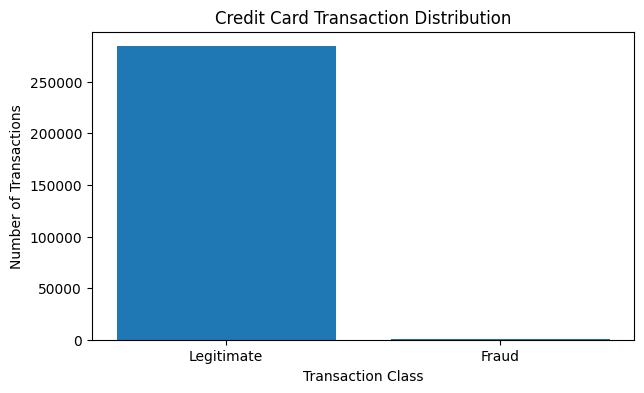

In [4]:
# Count legitimate and fraudulent transactions
class_counts = credit_df["Class"].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

print("\nClass Percentages:")
print((class_counts / len(credit_df) * 100).round(3))

# Show the class imbalance
plt.figure(figsize=(7, 4))
plt.bar(["Legitimate", "Fraud"], class_counts.values)
plt.title("Credit Card Transaction Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.show()

In [5]:
# Summarize transaction time and amount
# Anonymized V1–V28 features are excluded from this display
display(credit_df[["Time", "Amount"]].describe().round(2))

# Compare transaction amounts across classes
display(
    credit_df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)


,Time,Amount
count,284807.00,284807.00
mean,94813.86,88.35
std,47488.15,250.12
min,0.00,0.00
25%,54201.50,5.60
50%,84692.00,22.00
75%,139320.50,77.16
max,172792.00,25691.16


,count,mean,median,max
Class,,,,
0,284315,88.29,22.00,25691.16
1,492,122.21,9.25,2125.87


### 2. Preprocessing


In [6]:
# Remove duplicate transactions
credit_clean = credit_df.drop_duplicates().copy()

print("Original dataset:", credit_df.shape)
print("Cleaned dataset:", credit_clean.shape)
print("Duplicates remaining:", credit_clean.duplicated().sum())

Original dataset: (284807, 31)
Cleaned dataset: (283726, 31)


Duplicates remaining: 0


In [7]:
# Separate input features and target variable
X = credit_clean.drop(columns=["Class"])
y = credit_clean["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [8]:
# Split data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 198608
Testing samples: 85118

Training class distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Testing class distribution:
Class
0    84976
1      142
Name: count, dtype: int64


In [9]:
# Standardize features using training data statistics
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (198608, 30)
Testing data shape: (85118, 30)


### Preprocessing Summary

The original dataset contains 284,807 transactions with 30 input features and one target variable (`Class`). There were no missing values. We removed 1,081 exact duplicate rows, leaving 283,726 transactions.

Fraud is rare (approximately 0.17% of the original transactions), so accuracy alone can be misleading. A **stratified 70/30 train-test split** preserves the fraud proportion. Features are standardized with statistics learned from the training data only to prevent data leakage.


### 3. Model Training and Evaluation


In [10]:
# Train the logistic regression classifier
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

# Predict fraud labels on the test set
y_pred = log_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [11]:
# Compare the model with the majority-class baseline
accuracy = accuracy_score(y_test, y_pred)
baseline_accuracy = (y_test == 0).mean()
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print(f"All-legitimate baseline accuracy: {baseline_accuracy * 100:.2f}%")
print(f"Logistic Regression accuracy: {accuracy * 100:.2f}%")
print(f"Fraud detected: {tp} of {tp + fn} | Fraud missed: {fn}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


All-legitimate baseline accuracy: 99.83%
Logistic Regression accuracy: 99.91%
Fraud detected: 79 of 142 | Fraud missed: 63

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     84976
       Fraud       0.84      0.56      0.67       142

    accuracy                           1.00     85118
   macro avg       0.92      0.78      0.83     85118
weighted avg       1.00      1.00      1.00     85118



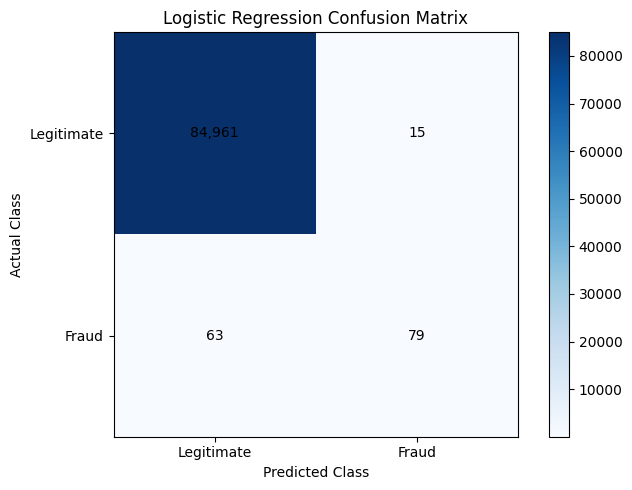

In [12]:
# Visualize actual vs. predicted fraud labels
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(cm, cmap="Blues")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

ax.set_xticks([0, 1], ["Legitimate", "Fraud"])
ax.set_yticks([0, 1], ["Legitimate", "Fraud"])
ax.set_title("Logistic Regression Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

### Part A: Results and Findings

Logistic regression achieved **99.91% accuracy** on the held-out test set. However, predicting every transaction as legitimate already achieves about **99.83% accuracy** because the dataset is highly imbalanced.

For the fraud class, precision was **0.84**, recall was **0.56**, and F1-score was **0.67**. The model identified only about 56% of actual fraud cases, missing roughly 44%.

**Conclusion:** Overall accuracy is insufficient for judging fraud detection. Recall, precision, F1-score, and the confusion matrix reveal the cost of missed fraud. This model is a useful baseline, but higher fraud recall should be investigated before practical deployment.


## Part B: Insurance Cost Prediction

### 1. Dataset Exploration

The objective is to predict medical insurance charges using linear regression. Predictors include age, sex, BMI, number of children, smoking status, and region. Unlike fraud detection, this is a **regression** task with a continuous numerical target.


In [13]:
# Load the insurance dataset
insurance_df = pd.read_csv(data_dir / "insurance.csv")

print("Dataset shape:", insurance_df.shape)
display(insurance_df.head())


Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [14]:
# Check data types, missing values, and duplicates
insurance_df.info()

print("\nMissing values:", insurance_df.isnull().sum().sum())
print("Duplicate rows:", insurance_df.duplicated().sum())

display(insurance_df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values: 0
Duplicate rows: 1


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


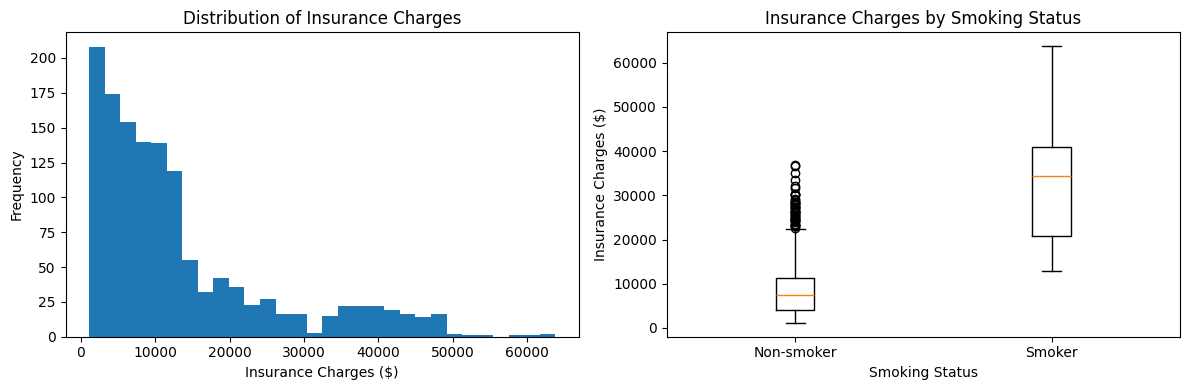

In [15]:
# Explore insurance charges and smoking status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(insurance_df["charges"], bins=30)
axes[0].set_title("Distribution of Insurance Charges")
axes[0].set_xlabel("Insurance Charges ($)")
axes[0].set_ylabel("Frequency")

non_smokers = insurance_df.loc[insurance_df["smoker"] == "no", "charges"]
smokers = insurance_df.loc[insurance_df["smoker"] == "yes", "charges"]
axes[1].boxplot([non_smokers, smokers])
axes[1].set_xticks([1, 2], ["Non-smoker", "Smoker"])
axes[1].set_title("Insurance Charges by Smoking Status")
axes[1].set_xlabel("Smoking Status")
axes[1].set_ylabel("Insurance Charges ($)")

plt.tight_layout()
plt.show()

### Exploratory Findings

Insurance charges have a right-skewed distribution with a smaller number of high-cost cases. The smoking-status boxplot shows that smokers tend to have higher charges in this dataset. These relationships are associations, not proof of causation.

### 2. Preprocessing


In [16]:
# Remove duplicates and encode categorical features
insurance_clean = insurance_df.drop_duplicates().copy()

insurance_encoded = pd.get_dummies(
    insurance_clean,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

print("Original shape:", insurance_df.shape)
print("Cleaned shape:", insurance_clean.shape)

display(insurance_encoded.head())

Original shape: (1338, 7)
Cleaned shape: (1337, 7)


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [17]:
# Separate predictors from insurance charges
X_insurance = insurance_encoded.drop(columns=["charges"])
y_insurance = insurance_encoded["charges"]

print("Features shape:", X_insurance.shape)
print("Target shape:", y_insurance.shape)

Features shape: (1337, 8)
Target shape: (1337,)


In [18]:
# Split insurance data into 70% training and 30% testing
X_train_ins, X_test_ins, y_train_ins, y_test_ins = train_test_split(
    X_insurance,
    y_insurance,
    test_size=0.30,
    random_state=42
)

print("Training samples:", X_train_ins.shape[0])
print("Testing samples:", X_test_ins.shape[0])

Training samples: 935
Testing samples: 402


### Preprocessing Summary

The insurance dataset has 1,338 records, **no missing values**, and **one duplicate row**. After removing the duplicate, 1,337 records remain.

Categorical variables (`sex`, `smoker`, and `region`) are represented by numerical dummy columns with one category dropped as a reference. The data is divided into **70% training** and **30% testing**. Linear regression is evaluated using MAE, MSE, RMSE, and R² rather than classification accuracy.


### 3. Model Training and Evaluation


In [19]:
# Train the linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train_ins, y_train_ins)

# Predict insurance charges
y_pred_ins = linear_model.predict(X_test_ins)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [20]:
# Evaluate prediction errors and model performance
mae = mean_absolute_error(y_test_ins, y_pred_ins)
mse = mean_squared_error(y_test_ins, y_pred_ins)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_ins, y_pred_ins)

print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): $4,181.82
Mean Squared Error (MSE): 38,940,169.92
Root Mean Squared Error (RMSE): $6,240.21
R² Score: 0.7724


In [21]:
# Display a few actual and predicted insurance charges
prediction_sample = pd.DataFrame({
    "Actual Charges ($)": y_test_ins.iloc[:5].to_numpy(),
    "Predicted Charges ($)": y_pred_ins[:5]
}).round(2)

display(prediction_sample)


,Actual Charges ($),Predicted Charges ($)
0,8688.86,8075.92
1,5708.87,5499.00
2,11436.74,14345.71
3,38746.36,31428.20
4,4463.21,8874.78


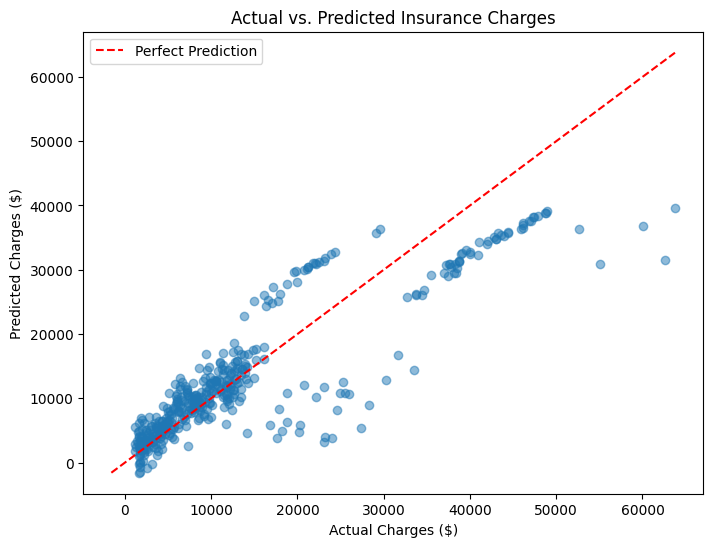

In [22]:
# Compare actual insurance charges with predictions
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_ins,
    y_pred_ins,
    alpha=0.5
)

min_charge = min(y_test_ins.min(), y_pred_ins.min())
max_charge = max(y_test_ins.max(), y_pred_ins.max())

plt.plot(
    [min_charge, max_charge],
    [min_charge, max_charge],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs. Predicted Insurance Charges")
plt.xlabel("Actual Charges ($)")
plt.ylabel("Predicted Charges ($)")
plt.legend()
plt.show()

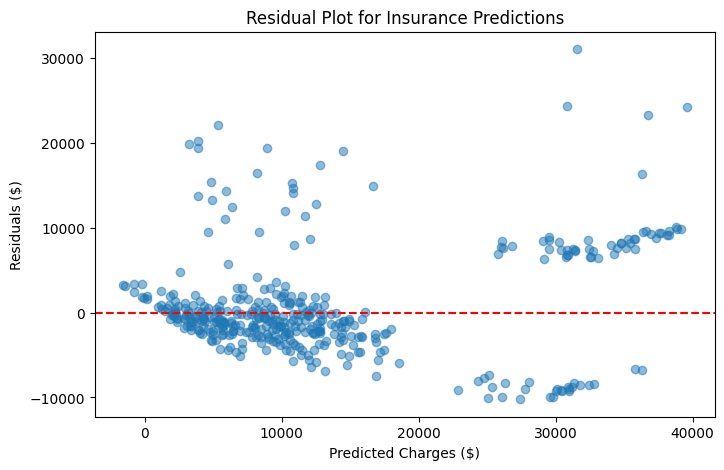

In [23]:
# Examine prediction errors
residuals = y_test_ins - y_pred_ins

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_ins, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.title("Residual Plot for Insurance Predictions")
plt.xlabel("Predicted Charges ($)")
plt.ylabel("Residuals ($)")
plt.show()

### Part B: Results and Findings

The linear regression model was trained on 70% of the cleaned insurance records and evaluated on the remaining 30%.

| Metric | Test result |
|---|---:|
| Mean Absolute Error (MAE) | $4,181.82 |
| Mean Squared Error (MSE) | 38,940,169.92 |
| Root Mean Squared Error (RMSE) | $6,240.21 |
| R² Score | 0.7724 |

The model explains approximately **77.24% of the variation** in insurance charges in the test set. Predictions differ from actual costs by about **$4,182 on average**, and the higher RMSE indicates that some errors are larger than typical.

**Conclusion:** Linear regression provides a useful baseline for estimating insurance charges, but individual predictions still have substantial uncertainty. Additional features or nonlinear approaches could be considered for improvement.


## Overall Conclusion

This lab demonstrated two supervised learning tasks using a **70/30 train-test split**.

- **Part A:** Logistic regression classified credit card transactions with **99.91% accuracy**, but only **56% fraud recall**. The severe class imbalance illustrates why classification performance should not be judged on accuracy alone.
- **Part B:** Linear regression predicted insurance costs with an **R² score of 0.7724** and an **MAE of $4,181.82**. Regression accuracy is better described by prediction errors and explained variance than by a percentage of correct classifications.

The main lesson is to select preprocessing methods and evaluation metrics that suit the data and the prediction task.

## References

1. Kaggle — [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
2. Kaggle — [Medical Cost Personal Dataset](https://www.kaggle.com/datasets/mirichoi0218/insurance)
3. Scikit-learn — [Machine Learning Documentation](https://scikit-learn.org/stable/)
